In [1]:
# Dataset setup:
# Extract your dataset archive manually in Google Colab or place the extracted folder
# at the dataset path used in the following cells.

Archive:  /content/tumor.zip
  inflating: brain_tumor_dataset/no/1 no.jpeg  
  inflating: brain_tumor_dataset/no/10 no.jpg  
  inflating: brain_tumor_dataset/no/11 no.jpg  
  inflating: brain_tumor_dataset/no/12 no.jpg  
  inflating: brain_tumor_dataset/no/13 no.jpg  
  inflating: brain_tumor_dataset/no/14 no.jpg  
  inflating: brain_tumor_dataset/no/15 no.jpg  
  inflating: brain_tumor_dataset/no/17 no.jpg  
  inflating: brain_tumor_dataset/no/18 no.jpg  
  inflating: brain_tumor_dataset/no/19 no.jpg  
  inflating: brain_tumor_dataset/no/2 no.jpeg  
  inflating: brain_tumor_dataset/no/20 no.jpg  
  inflating: brain_tumor_dataset/no/21 no.jpg  
  inflating: brain_tumor_dataset/no/22 no.jpg  
  inflating: brain_tumor_dataset/no/23 no.jpg  
  inflating: brain_tumor_dataset/no/24 no.jpg  
  inflating: brain_tumor_dataset/no/25 no.jpg  
  inflating: brain_tumor_dataset/no/26 no.jpg  
  inflating: brain_tumor_dataset/no/27 no.jpg  
  inflating: brain_tumor_dataset/no/28 no.jpg  
  inflating

In [2]:
import os
import shutil
import random

original_dataset_dir = "/content/brain_tumor_dataset"
base_dir = "/content/brain_tumor_split"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

# Create folders
for folder in ["train/yes", "train/no", "test/yes", "test/no"]:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

# Split function
def split_data(class_name, split_size=0.8):
    source_dir = os.path.join(original_dataset_dir, class_name)
    images = os.listdir(source_dir)
    random.seed(42)
    random.shuffle(images)

    split_index = int(len(images) * split_size)

    train_images = images[:split_index]
    test_images = images[split_index:]

    for img in train_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(train_dir, class_name, img))

    for img in test_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(test_dir, class_name, img))

# Split both classes
split_data("yes")
split_data("no")

print("Dataset split completed!")

Dataset split completed!


In [3]:
import os
train_labels=os.listdir('/content/brain_tumor_split/train')
test_labels=os.listdir('/content/brain_tumor_split/test')
print(train_labels)
print(test_labels)

['no', 'yes']
['no', 'yes']


In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 20

train_dir = "/content/brain_tumor_split/train"
test_dir = "/content/brain_tumor_split/test"

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

model = models.Sequential([
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS
)


Found 202 files belonging to 2 classes.
Found 51 files belonging to 2 classes.
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 823ms/step - accuracy: 0.5518 - loss: 0.7028 - val_accuracy: 0.8039 - val_loss: 0.4933
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.7822 - loss: 0.5110 - val_accuracy: 0.7647 - val_loss: 0.4514
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7787 - loss: 0.5255 - val_accuracy: 0.7647 - val_loss: 0.4552
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7721 - loss: 0.4557 - val_accuracy: 0.8235 - val_loss: 0.4042
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8051 - loss: 0.3937 - val_accuracy: 0.8235 - val_loss: 0.3970
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8842 - loss: 0.2859 - val_accuracy: 0.8824 - val_loss: 0.3386
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9148 - loss: 0.2354 - val_accuracy: 0.9216 - val_loss: 0.3014
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9350 - loss: 0.2168 - val_accuracy: 0.9216 - val_loss: 0.2676
Epoch 9/2

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


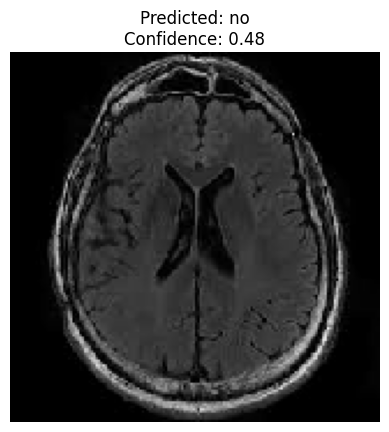

Raw Probability: 0.47519758
Predicted Class: no


In [39]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
IMG_SIZE = 160
class_names = ['no', 'yes']
img_path = "/content/brain_tumor_split/test/no/50 no.jpg"   # put your image path here

img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0
prediction = model.predict(img_array)

probability = prediction[0][0]

if probability >=0.476:
    predicted_class = class_names[1]
else:
    predicted_class = class_names[0]
plt.imshow(img)
plt.title(f"Predicted: {predicted_class}\nConfidence: {probability:.2f}")
plt.axis("off")
plt.show()
print("Raw Probability:", probability)
print("Predicted Class:", predicted_class)

In [ ]:
# =========================
# SAVE MODEL
# =========================
model.save("brain_tumor_model.keras")
print("Model saved successfully!")

# =========================
# PLOT ACCURACY
# =========================
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.show()

### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.